# IMDb Movies: Data Collection, Data Cleaning and Exploratory Data Analysis

## Problem Statement

The objective of this project is to analyze movie characteristics and investigate their relationship with audience ratings and commercial performance. The project will use Python libraries to collect or obtain authorized movie data, clean and transform the dataset, identify missing values and outliers, and perform exploratory data analysis.

The analysis will focus on variables such as movie title, release year, genre, runtime, IMDb rating, number of votes, and gross revenue where available.

The project aims to identify patterns in movie ratings, compare genres, explore the relationship between ratings and audience votes, and investigate which movie characteristics are associated with higher gross revenue.

The final deliverables will include the original dataset, cleaned CSV file, Python code, visualizations, interpretations, conclusions, and project presentation.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from pathlib import Path
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 20)
print("Setup complete")

Setup complete


In [3]:
url = "https://datasets.imdbws.com/title.basics.tsv.gz"
df = pd.read_csv(url, sep="\t", compression="gzip", low_memory=False, na_values="\\N")
df.head()

,tconst,titleType,primaryTitle,originalTitle,isAdult,startYear,endYear,runtimeMinutes,genres
0,tt0000001,short,Carmencita,Carmencita,0,1894.0,NaN,1,"Documentary,Short"
1,tt0000002,short,Le clown et ses chiens,Le clown et ses chiens,0,1892.0,NaN,5,"Animation,Short"
2,tt0000003,short,Poor Pierrot,Pauvre Pierrot,0,1892.0,NaN,5,"Animation,Comedy,Romance"
3,tt0000004,short,Un bon bock,Un bon bock,0,1892.0,NaN,12,"Animation,Short"
4,tt0000005,short,Blacksmith Scene,Blacksmith Scene,0,1893.0,NaN,1,Short


In [4]:
df = df[df["titleType"] == "movie"].copy()
df = df[["tconst", "primaryTitle", "startYear", "runtimeMinutes", "genres"]]
df = df.rename(columns={
    "tconst": "movie_id",
    "primaryTitle": "movie_title",
    "startYear": "release_year",
    "runtimeMinutes": "runtime_minutes"
})
df.head()

,movie_id,movie_title,release_year,runtime_minutes,genres
8,tt0000009,Miss Jerry,1894.0,45,Romance
144,tt0000147,The Corbett-Fitzsimmons Fight,1897.0,100,"Documentary,News,Sport"
498,tt0000502,Bohemios,1905.0,100,NaN
570,tt0000574,The Story of the Kelly Gang,1906.0,70,"Action,Adventure,Biography"
587,tt0000591,The Prodigal Son,1907.0,90,Drama


In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Data types:")
print(df.dtypes)
print("Missing values:")
print(df.isnull().sum())

Rows: 759763
Columns: 5
Data types:
movie_id            object
movie_title         object
release_year       float64
runtime_minutes     object
genres              object
dtype: object
Missing values:
movie_id                0
movie_title             3
release_year       113728
runtime_minutes    271543
genres              77843
dtype: int64


In [6]:
df["release_year"] = pd.to_numeric(df["release_year"], errors="coerce")
df["runtime_minutes"] = pd.to_numeric(df["runtime_minutes"], errors="coerce")
df["movie_title"] = df["movie_title"].replace("", np.nan)
df["genres"] = df["genres"].replace("", np.nan)
df = df.dropna(subset=["movie_title"])
df = df.drop_duplicates(subset=["movie_id"])
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Missing values:")
print(df.isnull().sum())
print("Data types:")
print(df.dtypes)

Rows: 759760
Columns: 5
Missing values:
movie_id                0
movie_title             0
release_year       113728
runtime_minutes    271542
genres              77843
dtype: int64
Data types:
movie_id            object
movie_title         object
release_year       float64
runtime_minutes    float64
genres              object
dtype: object


In [7]:
rating_url = "https://datasets.imdbws.com/title.ratings.tsv.gz"
ratings_df = pd.read_csv(
    rating_url,
    sep="\t",
    compression="gzip",
    na_values="\\N"
)
ratings_df = ratings_df.rename(columns={
    "tconst": "movie_id",
    "averageRating": "imdb_rating",
    "numVotes": "num_votes"
})
df = df.merge(ratings_df, on="movie_id", how="left")
print("Rows:",df.shape[0])
print("Columns:", df.shape[1])
print(df.head())

Rows: 759760
Columns: 7
    movie_id                    movie_title  release_year  runtime_minutes  \
0  tt0000009                     Miss Jerry        1894.0             45.0   
1  tt0000147  The Corbett-Fitzsimmons Fight        1897.0            100.0   
2  tt0000502                       Bohemios        1905.0            100.0   
3  tt0000574    The Story of the Kelly Gang        1906.0             70.0   
4  tt0000591               The Prodigal Son        1907.0             90.0   

                       genres  imdb_rating  num_votes  
0                     Romance          5.3      239.0  
1      Documentary,News,Sport          5.3      615.0  
2                         NaN          3.7       27.0  
3  Action,Adventure,Biography          6.0     1101.0  
4                       Drama          5.1       43.0  


In [8]:
df = df.dropna(subset=[
    "release_year",
    "runtime_minutes",
    "genres",
    "imdb_rating",
    "num_votes"
]).copy()
df["release_year"] = df["release_year"].astype(int)
df["runtime_minutes"] = df["runtime_minutes"].astype(int)
df["num_votes"] = df["num_votes"].astype(int)
df = df[df["runtime_minutes"] > 0]
df = df.drop_duplicates(subset=["movie_id"])
df.to_csv("imdb_movies.csv", index=False)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("CSV saved")

Rows: 313307
Columns: 7
CSV saved


In [9]:
print("Shape:", df.shape)
print("Column names:", df.columns.tolist())
print("Data types:")
print(df.dtypes)
print("Missing values:")
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Summary statistics:")
display(df.describe())

Shape: (313307, 7)
Column names: ['movie_id', 'movie_title', 'release_year', 'runtime_minutes', 'genres', 'imdb_rating', 'num_votes']
Data types:
movie_id            object
movie_title         object
release_year         int64
runtime_minutes      int64
genres              object
imdb_rating        float64
num_votes            int64
dtype: object
Missing values:
movie_id           0
movie_title        0
release_year       0
runtime_minutes    0
genres             0
imdb_rating        0
num_votes          0
dtype: int64
Duplicate rows: 0
Summary statistics:


,release_year,runtime_minutes,imdb_rating,num_votes
count,313307.000000,313307.000000,313307.000000,3.133070e+05
mean,1998.299096,94.466354,6.136707,4.153286e+03
std,26.036033,137.362412,1.352109,4.039917e+04
min,1894.000000,1.000000,1.000000,5.000000e+00
25%,1983.000000,80.000000,5.300000,2.500000e+01
50%,2009.000000,91.000000,6.200000,8.200000e+01
75%,2018.000000,104.000000,7.000000,4.060000e+02
max,2026.000000,51420.000000,10.000000,3.253246e+06


In [10]:
df["movie_age"] = 2026 - df["release_year"]
print("Shape:", df.shape)
display(df.head())

Shape: (313307, 8)


,movie_id,movie_title,release_year,runtime_minutes,genres,imdb_rating,num_votes,movie_age
0,tt0000009,Miss Jerry,1894,45,Romance,5.3,239,132
1,tt0000147,The Corbett-Fitzsimmons Fight,1897,100,"Documentary,News,Sport",5.3,615,129
3,tt0000574,The Story of the Kelly Gang,1906,70,"Action,Adventure,Biography",6.0,1101,120
4,tt0000591,The Prodigal Son,1907,90,Drama,5.1,43,119
8,tt0000679,The Fairylogue and Radio-Plays,1908,120,"Adventure,Fantasy",5.0,86,118


count    313307.000000
mean         94.466354
std         137.362412
min           1.000000
25%          80.000000
50%          91.000000
75%         104.000000
max       51420.000000
Name: runtime_minutes, dtype: float64

Runtime above 300 minutes: 236
Runtime above 600 minutes: 43


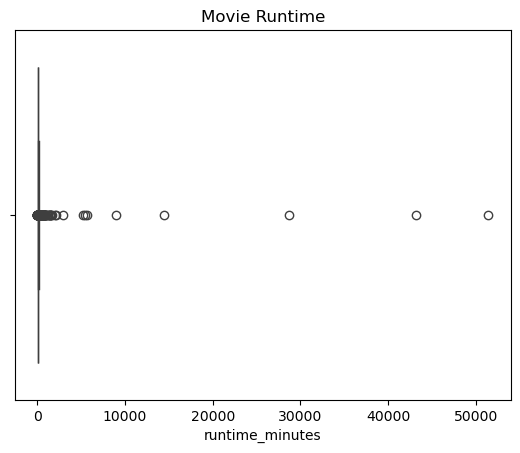

In [11]:
display(df["runtime_minutes"].describe())
print("Runtime above 300 minutes:", (df["runtime_minutes"] > 300).sum())
print("Runtime above 600 minutes:", (df["runtime_minutes"] > 600).sum())
sns.boxplot(x=df["runtime_minutes"])
plt.title("Movie Runtime")
plt.show()

In [12]:
df["movie_age"] = 2026 - df["release_year"]
print("Missing age:", df["movie_age"].isnull().sum())
display(
    df.nlargest(15, "runtime_minutes")[
        ["movie_title", "release_year", "runtime_minutes", "genres", "imdb_rating"]
    ]
)

Missing age: 0


,movie_title,release_year,runtime_minutes,genres,imdb_rating
730086,Logistics,2012,51420,Documentary,6.2
582222,Ambiancé,2020,43200,Documentary,2.9
275304,Carnets Filmés (Liste Complète),2019,28643,Documentary,6.7
447013,Modern Times Forever,2011,14400,Documentary,6.4
427964,Beijing 2003,2004,9000,Documentary,7.4
371840,Matrjoschka,2006,5700,Drama,5.4
656512,London EC1,2015,5460,"Comedy,Drama,Mystery",6.4
155661,The Cure for Insomnia,1987,5220,"Documentary,Music",4.7
174833,The Longest Most Meaningless Movie in the World,1970,2880,"Documentary,Drama,History",5.2
247655,Five-Year Diary,1982,2160,Documentary,7.5


In [13]:
cols = ["imdb_rating", "runtime_minutes", "num_votes", "release_year", "movie_age"]
display(df[cols].describe().T)
for c in cols:
    print(c)
    print("Mean:", round(df[c].mean(), 2))
    print("Median:", round(df[c].median(), 2))
    print("Mode:", df[c].mode().iloc[0])
    print("Std:", round(df[c].std(), 2))
    print()

,count,mean,std,min,25%,50%,75%,max
imdb_rating,313307.0,6.136707,1.352109,1.0,5.3,6.2,7.0,10.0
runtime_minutes,313307.0,94.466354,137.362412,1.0,80.0,91.0,104.0,51420.0
num_votes,313307.0,4153.286390,40399.167860,5.0,25.0,82.0,406.0,3253246.0
release_year,313307.0,1998.299096,26.036033,1894.0,1983.0,2009.0,2018.0,2026.0
movie_age,313307.0,27.700904,26.036033,0.0,8.0,17.0,43.0,132.0


imdb_rating
Mean: 6.14
Median: 6.2
Mode: 6.4
Std: 1.35

runtime_minutes
Mean: 94.47
Median: 91.0
Mode: 90
Std: 137.36

num_votes
Mean: 4153.29
Median: 82.0
Mode: 11
Std: 40399.17

release_year
Mean: 1998.3
Median: 2009.0
Mode: 2023
Std: 26.04

movie_age
Mean: 27.7
Median: 17.0
Mode: 3
Std: 26.04



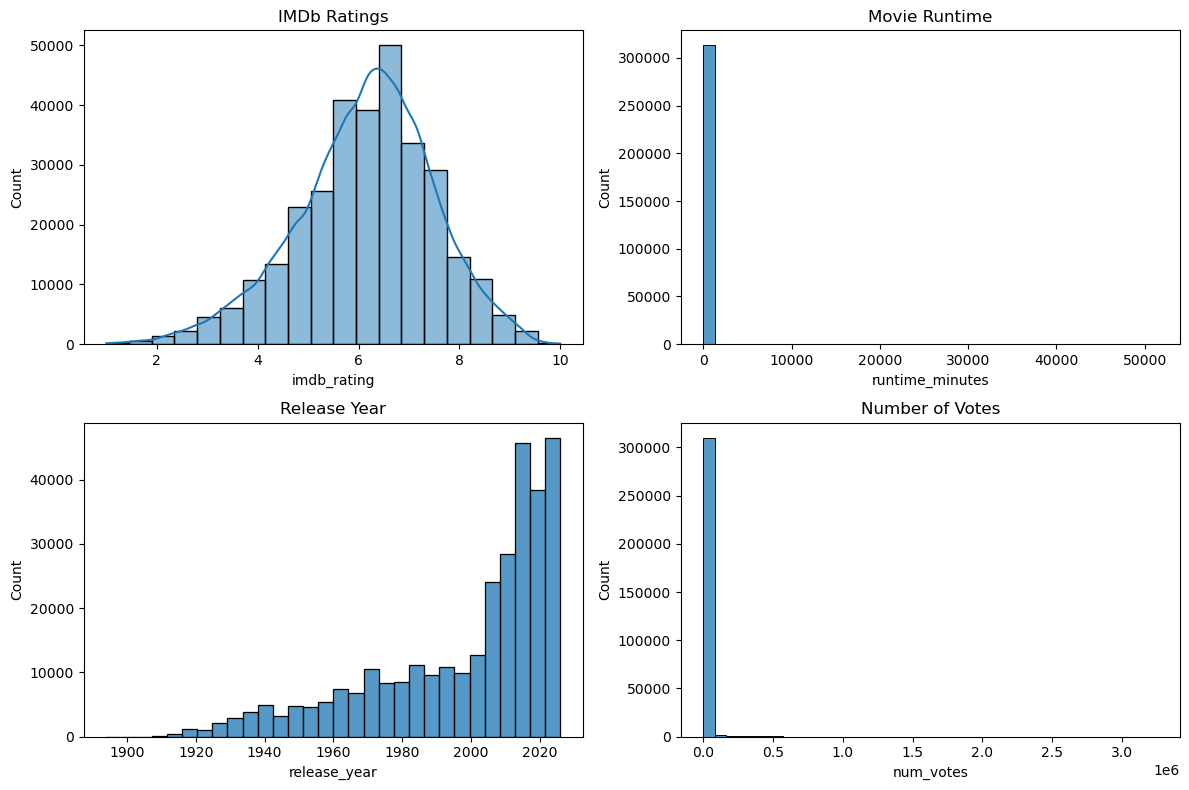

In [14]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(data=df, x="imdb_rating", bins=20, kde=True, ax=ax[0, 0])
sns.histplot(data=df, x="runtime_minutes", bins=40, ax=ax[0, 1])
sns.histplot(data=df, x="release_year", bins=30, ax=ax[1, 0])
sns.histplot(data=df, x="num_votes", bins=40, ax=ax[1, 1])
ax[0, 0].set_title("IMDb Ratings")
ax[0, 1].set_title("Movie Runtime")
ax[1, 0].set_title("Release Year")
ax[1, 1].set_title("Number of Votes")
plt.tight_layout()
plt.show()

genres
Drama          148179
Comedy          78922
Documentary     54043
Romance         35327
Action          32556
Crime           29014
Thriller        28274
Horror          25595
Adventure       19754
Mystery         13367
Family          12453
Biography       10812
Fantasy         10145
History          9469
Music            9132
Name: count, dtype: int64

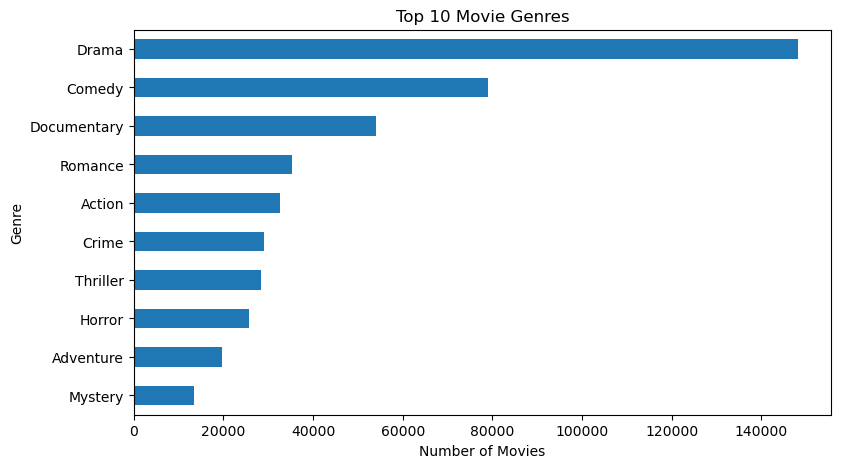

In [15]:
genre_counts = df["genres"].str.split(",").explode().value_counts()
display(genre_counts.head(15))
genre_counts.head(10).sort_values().plot(kind="barh", figsize=(9, 5))
plt.title("Top 10 Movie Genres")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")
plt.show()

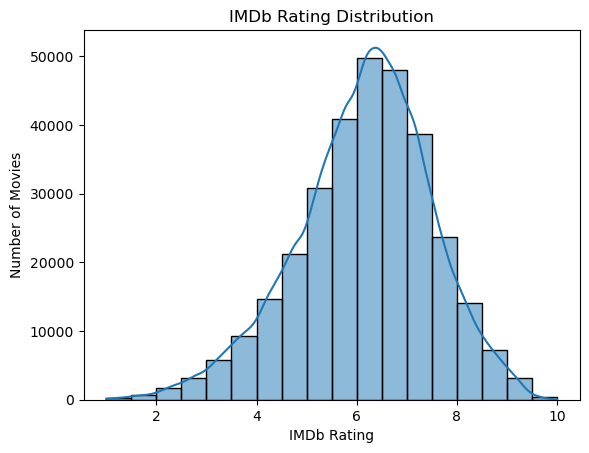

In [16]:
sns.histplot(data=df, x="imdb_rating", bins=18, kde=True)
plt.title("IMDb Rating Distribution")
plt.xlabel("IMDb Rating")
plt.ylabel("Number of Movies")
plt.show()

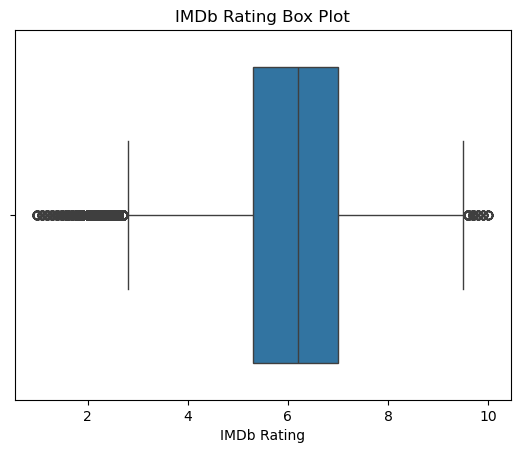

In [17]:
sns.boxplot(x=df["imdb_rating"])
plt.title("IMDb Rating Box Plot")
plt.xlabel("IMDb Rating")
plt.show()

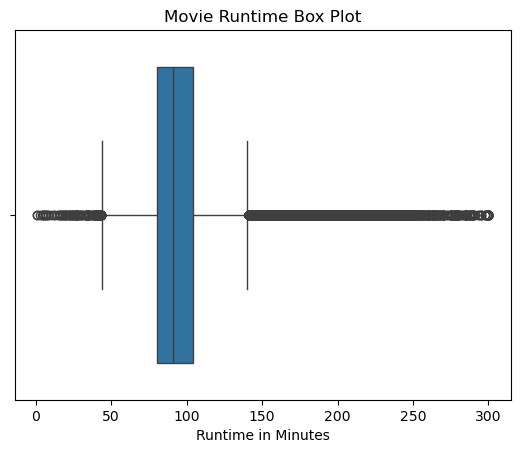

All movies: 313307
Movies up to 300 minutes: 313071


In [18]:
runtime_df = df[df["runtime_minutes"] <= 300]
sns.boxplot(x=runtime_df["runtime_minutes"])
plt.title("Movie Runtime Box Plot")
plt.xlabel("Runtime in Minutes")
plt.show()
print("All movies:", len(df))
print("Movies up to 300 minutes:", len(runtime_df))

### Univariate Analysis — Interpretation

1. The average IMDb rating is approximately 6.14, while the median rating is 6.2.
2. The average movie runtime is approximately 94.47 minutes, with a median runtime of 91 minutes.
3. The maximum runtime is much higher than the typical runtime because the dataset contains exceptionally long films.
4. The number of votes is strongly right-skewed: most movies receive relatively few votes, while a small number receive very large numbers of votes.
5. The median release year is 2009, indicating that half of the analyzed movies were released in or before that year.
6. The genre frequency chart will identify the most common genres represented in the dataset.
7. Box plots help identify unusual observations, but these observations must be investigated before deciding whether they are errors.

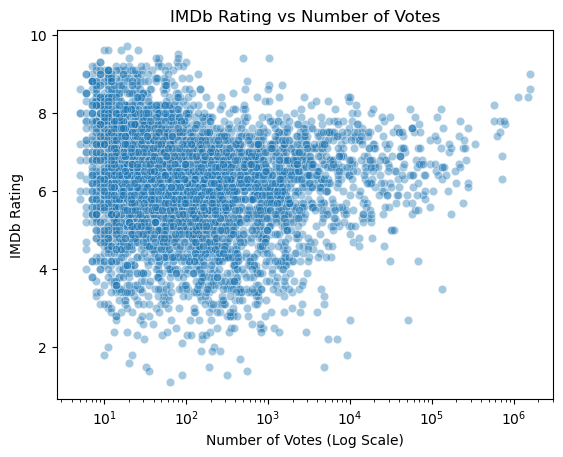

In [19]:
sns.scatterplot(
    data=df[df["num_votes"] > 0].sample(5000, random_state=42),
    x="num_votes",
    y="imdb_rating",
    alpha=0.4
)
plt.xscale("log")
plt.title("IMDb Rating vs Number of Votes")
plt.xlabel("Number of Votes (Log Scale)")
plt.ylabel("IMDb Rating")
plt.show()

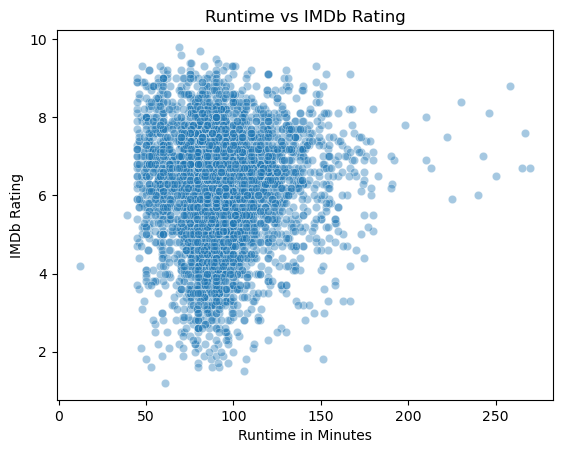

In [20]:
sample_df = df[df["runtime_minutes"] <= 300].sample(5000, random_state=42)
sns.scatterplot(
    data=sample_df,
    x="runtime_minutes",
    y="imdb_rating",
    alpha=0.4
)
plt.title("Runtime vs IMDb Rating")
plt.xlabel("Runtime in Minutes")
plt.ylabel("IMDb Rating")
plt.show()

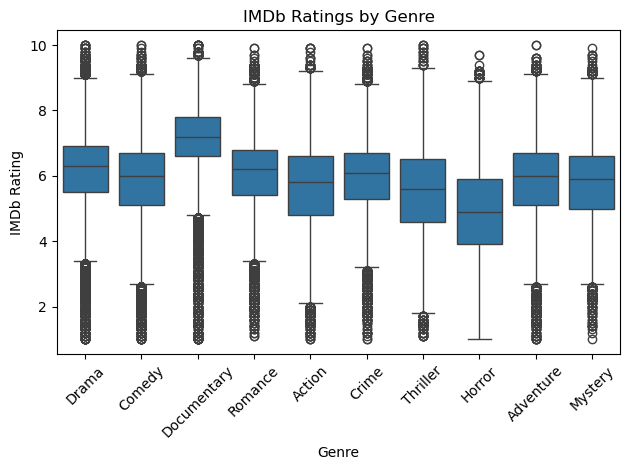

In [21]:
genre_df = df.assign(genre=df["genres"].str.split(",")).explode("genre")
top_genres = genre_df["genre"].value_counts().head(10).index
genre_sample = genre_df[genre_df["genre"].isin(top_genres)]
sns.boxplot(
    data=genre_sample,
    x="genre",
    y="imdb_rating",
    order=top_genres
)
plt.title("IMDb Ratings by Genre")
plt.xlabel("Genre")
plt.ylabel("IMDb Rating")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

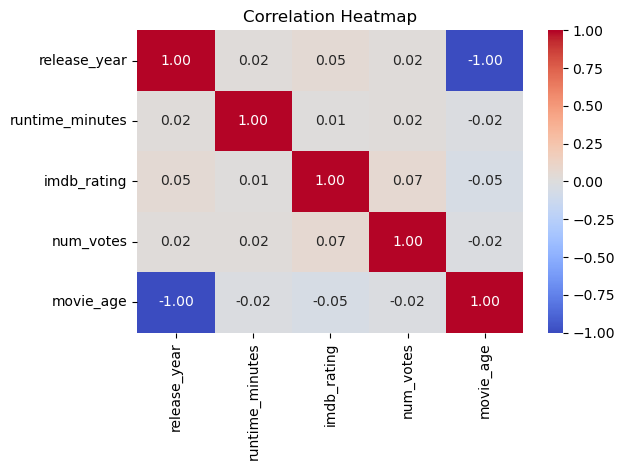

,release_year,runtime_minutes,imdb_rating,num_votes,movie_age
release_year,1.000000,0.019285,0.052341,0.023270,-1.000000
runtime_minutes,0.019285,1.000000,0.008657,0.016729,-0.019285
imdb_rating,0.052341,0.008657,1.000000,0.066076,-0.052341
num_votes,0.023270,0.016729,0.066076,1.000000,-0.023270
movie_age,-1.000000,-0.019285,-0.052341,-0.023270,1.000000


In [22]:
num_df = df[
    ["release_year", "runtime_minutes", "imdb_rating", "num_votes", "movie_age"]
]
corr = num_df.corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()
display(corr)

In [23]:
genre_summary = genre_df.groupby("genre").agg(
    movie_count=("movie_id", "count"),
    avg_rating=("imdb_rating", "mean"),
    median_rating=("imdb_rating", "median"),
    avg_votes=("num_votes", "mean")
)
genre_summary = genre_summary.sort_values("movie_count", ascending=False)
display(genre_summary.head(15).round(2))

,movie_count,avg_rating,median_rating,avg_votes
genre,,,,
Drama,148179,6.19,6.3,4411.63
Comedy,78922,5.88,6.0,4937.58
Documentary,54043,7.17,7.2,338.72
Romance,35327,6.08,6.2,4466.78
Action,32556,5.71,5.8,12101.86
Crime,29014,5.96,6.1,8739.01
Thriller,28274,5.54,5.6,8016.01
Horror,25595,4.92,4.9,5424.38
Adventure,19754,5.87,6.0,17235.57


In [24]:
df["release_period"] = pd.cut(
    df["release_year"],
    bins=[1800, 1950, 1980, 2000, 2020, 2030],
    labels=["Before 1951", "1951-1980", "1981-2000", "2001-2020", "2021-2030"]
)
genre_df = df.assign(genre=df["genres"].str.split(",")).explode("genre")
top_genres = genre_df["genre"].value_counts().head(5).index
cross_df = pd.crosstab(
    genre_df["release_period"],
    genre_df["genre"]
)
display(cross_df[top_genres])

genre,Drama,Comedy,Documentary,Romance,Action
release_period,,,,,
Before 1951,14588,7314,403,4879,1644
1951-1980,28135,14527,2041,6489,5376
1981-2000,23633,13015,4121,5884,7220
2001-2020,59890,32488,34856,13773,12894
2021-2030,21933,11578,12622,4302,5422


In [25]:
df.to_csv("imdb_movies.csv", index=False)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("CSV saved")

Rows: 313307
Columns: 9
CSV saved


In [26]:
print("Shape:", df.shape)
print("Missing values:")
print(df.isnull().sum())
print("Duplicate IDs:", df["movie_id"].duplicated().sum())
print("Minimum year:", df["release_year"].min())
print("Maximum year:", df["release_year"].max())
print("Minimum rating:", df["imdb_rating"].min())
print("Maximum rating:", df["imdb_rating"].max())
print("Minimum runtime:", df["runtime_minutes"].min())
print("Maximum runtime:", df["runtime_minutes"].max())

Shape: (313307, 9)
Missing values:
movie_id           0
movie_title        0
release_year       0
runtime_minutes    0
genres             0
imdb_rating        0
num_votes          0
movie_age          0
release_period     0
dtype: int64
Duplicate IDs: 0
Minimum year: 1894
Maximum year: 2026
Minimum rating: 1.0
Maximum rating: 10.0
Minimum runtime: 1
Maximum runtime: 51420


In [27]:
df.to_csv("imdb_movies.csv", index=False)
print("Final CSV saved")

Final CSV saved


In [28]:
import os
print(os.getcwd())

C:\Users\abhip


In [29]:
print("Shape:", df.shape)
print("Missing values:")
print(df.isnull().sum())
print("Duplicate IDs:", df["movie_id"].duplicated().sum())
print("Year range:", df["release_year"].min(), "-", df["release_year"].max())
print("Rating range:", df["imdb_rating"].min(), "-", df["imdb_rating"].max())
print("Runtime range:", df["runtime_minutes"].min(), "-", df["runtime_minutes"].max())

Shape: (313307, 9)
Missing values:
movie_id           0
movie_title        0
release_year       0
runtime_minutes    0
genres             0
imdb_rating        0
num_votes          0
movie_age          0
release_period     0
dtype: int64
Duplicate IDs: 0
Year range: 1894 - 2026
Rating range: 1.0 - 10.0
Runtime range: 1 - 51420


In [30]:
runtime_df = df[df["runtime_minutes"] <= 300].copy()
print("All movies:", len(df))
print("Typical runtime subset:", len(runtime_df))
print("Excluded from runtime subset:", len(df) - len(runtime_df))
display(runtime_df["runtime_minutes"].describe())

All movies: 313307
Typical runtime subset: 313071
Excluded from runtime subset: 236


count    313071.000000
mean         93.666545
std          23.732658
min           1.000000
25%          80.000000
50%          91.000000
75%         104.000000
max         300.000000
Name: runtime_minutes, dtype: float64

In [ ]:
cd "$env:USERPROFILE\Desktop\EDA_IMDB"
jupyter notebook